# 06 Structure beyond beta: the one-factor null

If the only thing linking stocks were their exposure to the market, how dense would the Graphical Lasso network be? For each year I simulate 200 beta-only markets with the same days, tickers, loading profiles and average correlation, and run the same Graphical Lasso at the same fixed penalty. Observed density above the simulated range points to links between stocks that the market factor does not explain.

Rerunning all 200 simulations per year takes one to two hours, so by default the notebook reads the saved results. Set `RERUN = True` to regenerate them, or `SIMS = 20` for a quick pass.

In [1]:
import sys
sys.path.insert(0, "..")

from IPython.display import Image
import pandas as pd
import src.one_factor_null as null

RERUN = False       # True reruns the simulations; False reads figures/one_factor_null.csv
SIMS = 200          # about 1-2 hours at 200; use 20 for a quick pass

In [2]:
results = (null.main(sims=SIMS) if RERUN
           else pd.read_csv("../figures/one_factor_null.csv", index_col="year"))
results

,n_days,n_tickers,mean_corr,observed_density,null_mean,null_sd,z,p_excess,null_failed
year,,,,,,,,,
2004,100,410,0.228,0.0079,0.0000,0.0001,148.86,0.0050,0
2005,98,409,0.191,0.0059,0.0000,0.0000,496.99,0.0050,0
2006,113,410,0.216,0.0082,0.0000,0.0000,505.78,0.0050,0
2007,130,405,0.332,0.0209,0.0006,0.0011,17.79,0.0050,0
2008,125,406,0.437,0.0523,0.0165,0.0132,2.71,0.0249,0
2009,111,410,0.404,0.0486,0.0144,0.0125,2.74,0.0249,0
2010,99,411,0.456,0.0569,0.0384,0.0208,0.89,0.1990,0
2011,105,416,0.547,0.0803,0.0858,0.0187,-0.30,0.6598,7
2012,104,425,0.303,0.0211,0.0006,0.0008,27.10,0.0050,0


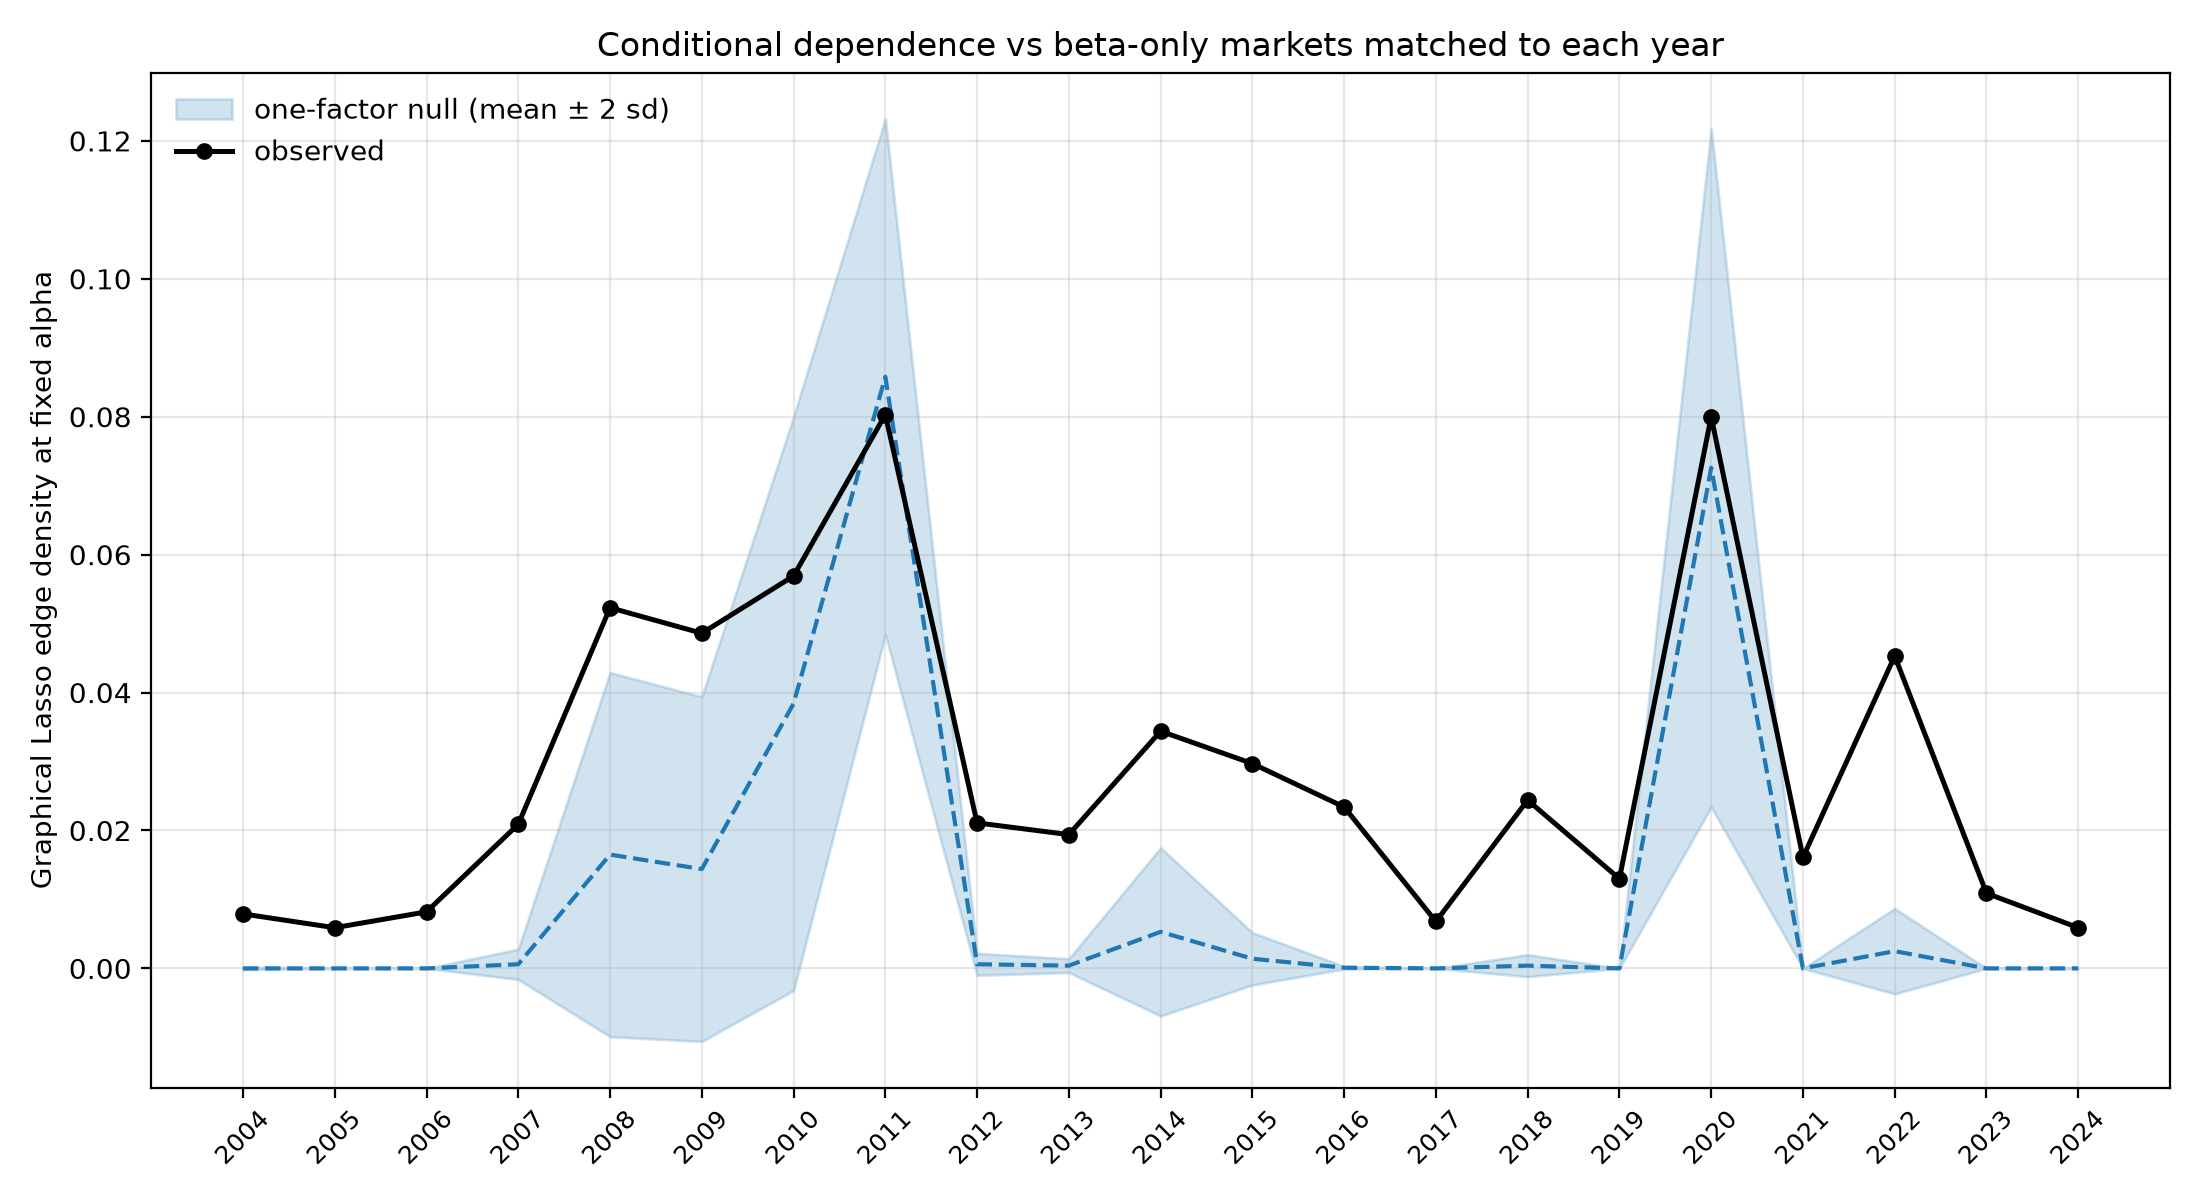

In [3]:
Image(filename="../figures/one_factor_null.png")

In 18 of 21 years the observed density is above the null. In calm years the null density is exactly zero, while the real market always keeps some links.

The exceptions are 2010, 2011 and 2020, the highest-correlation years. There the observed density sits within the range beta alone produces, and in 2011 it is slightly below the null mean. The network densification visible in the crisis-year animations can't be told apart from the effect of high correlation on the estimator.

Notebook 07 runs two harder versions of this test. With fat-tailed noise the excess is significant in 7 of 21 years, and a market-plus-sector null explains most of the network in every year, so the links found here are mostly sector structure.

## Summary figure

The three results in one figure: the correlation series with its PC1 control, the volatility-adjusted series, and observed edge density against the null band.

saved: /Users/ammarnagri/Documents/GitHub/Changes-in-Stock-Market-Structure/figures/summary.png


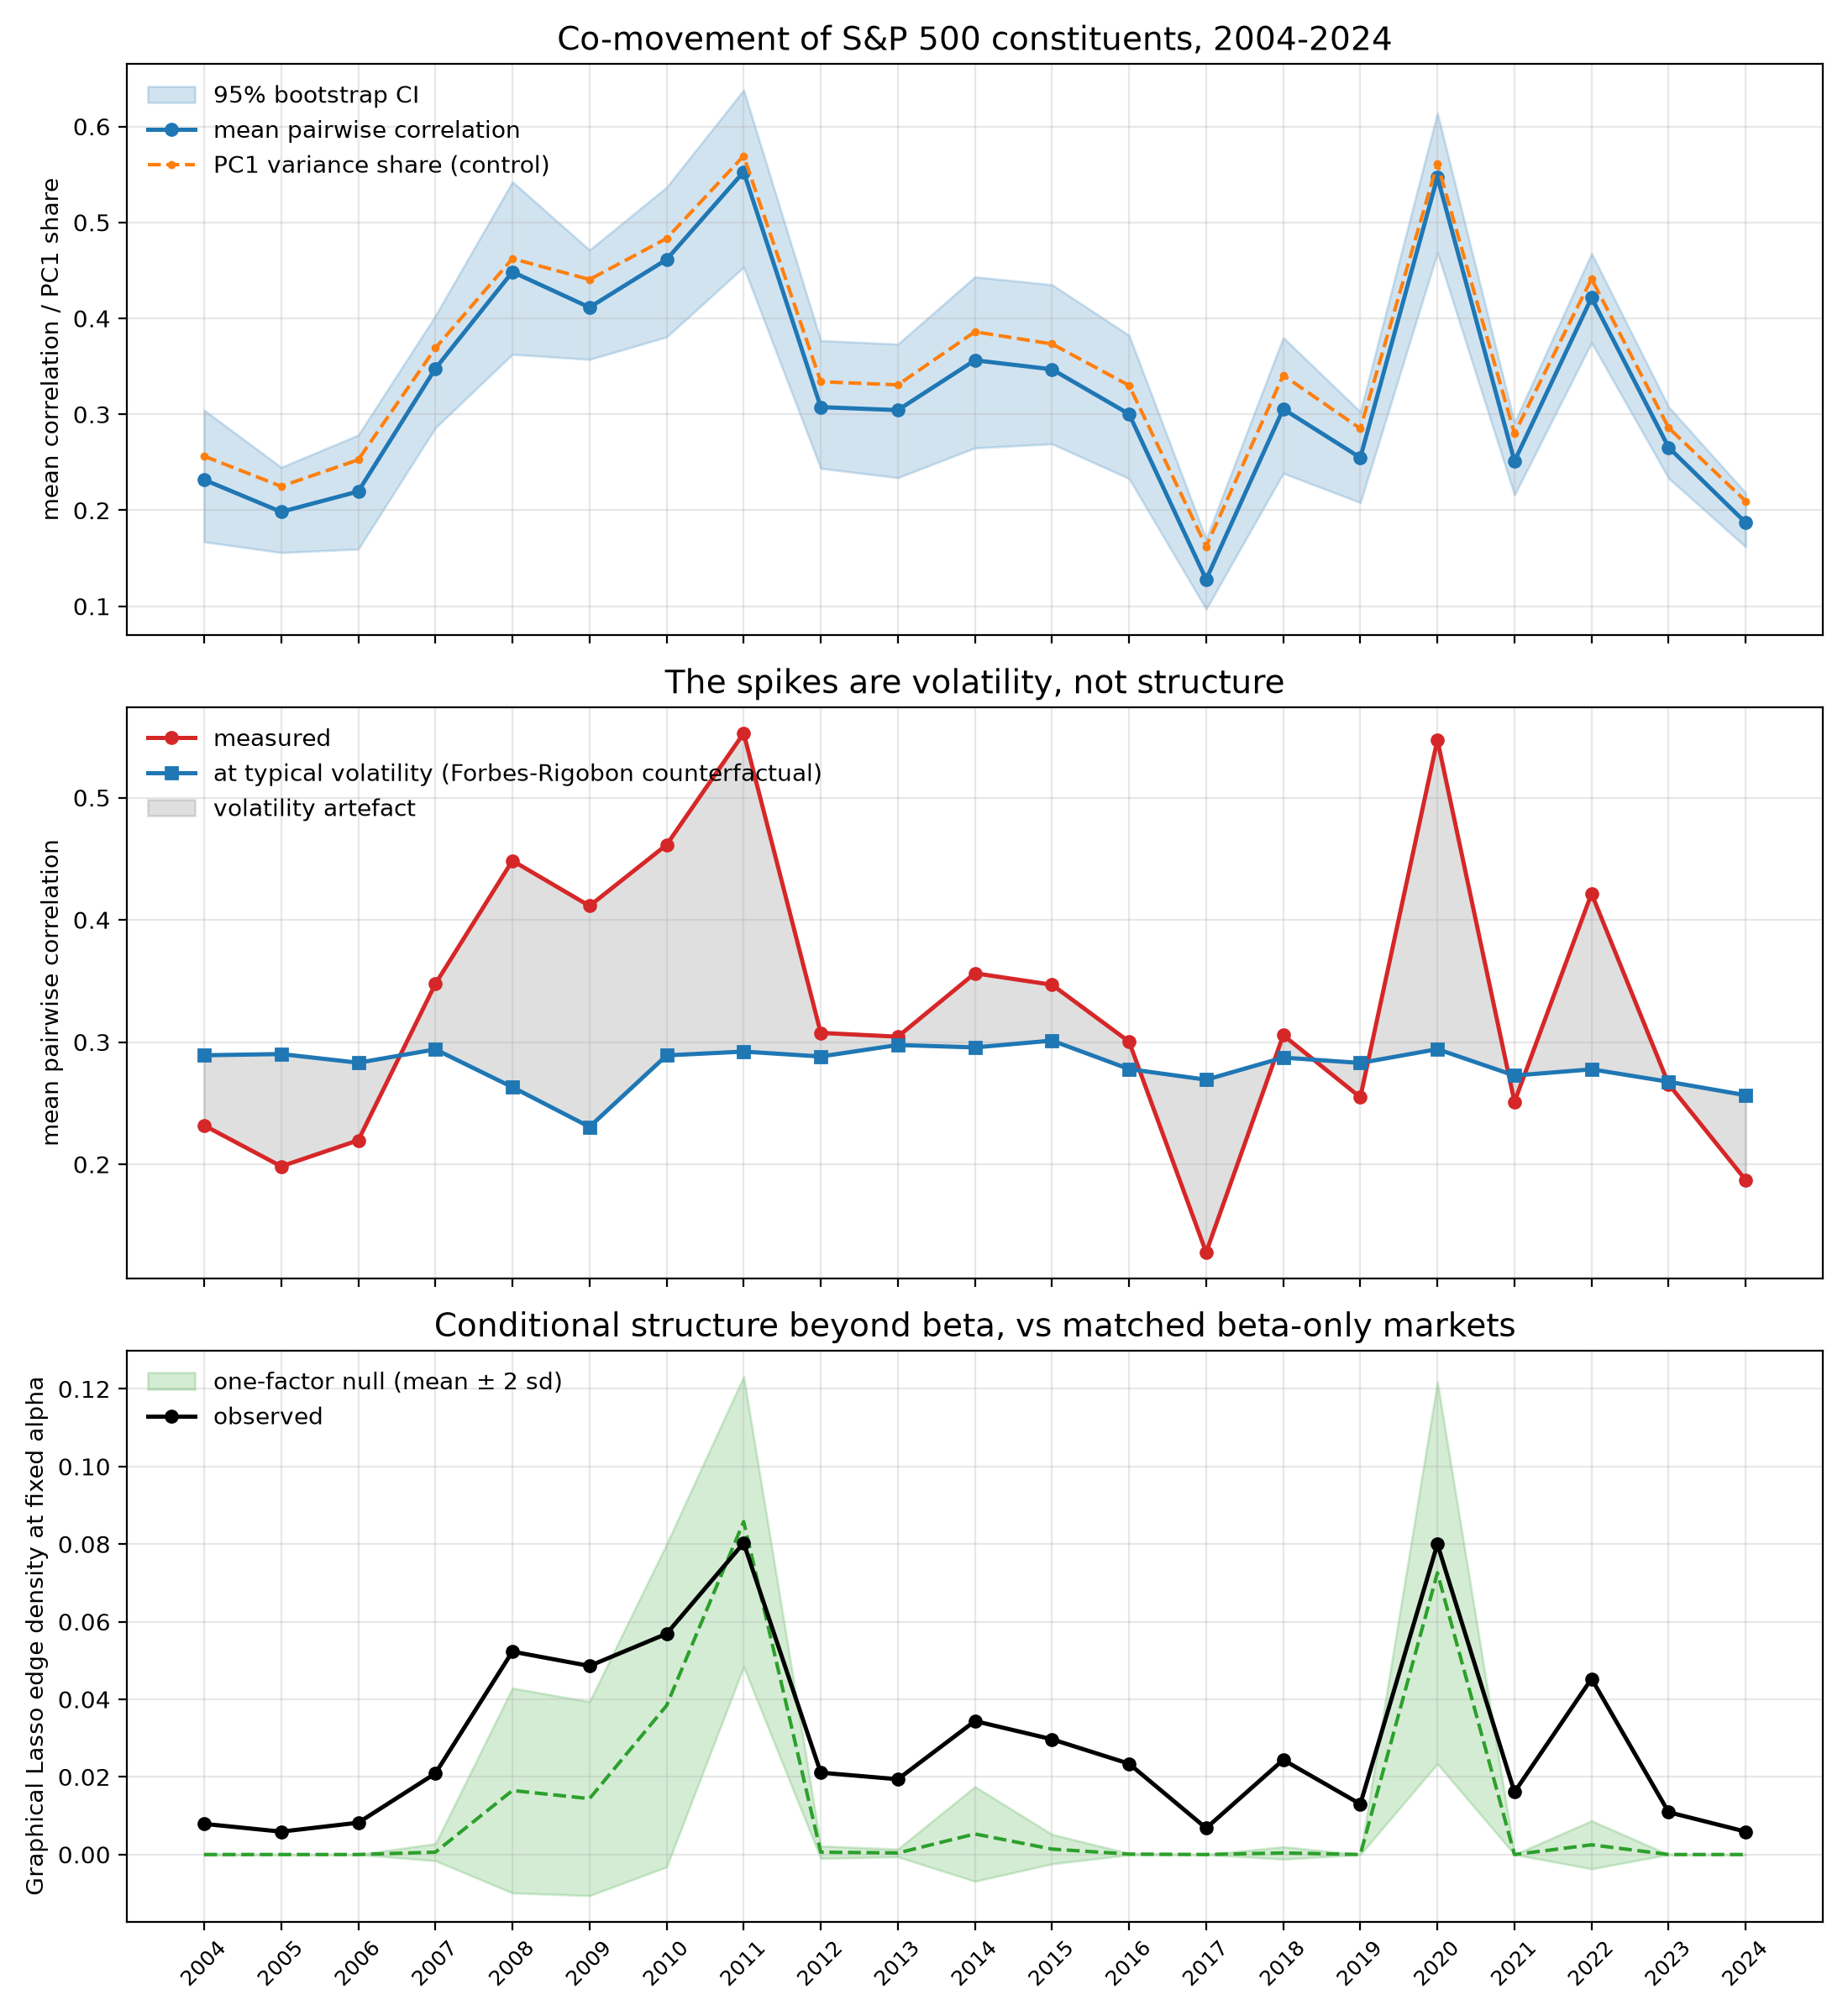

In [4]:
import src.plot_summary as plot_summary
plot_summary.main()
Image(filename="../figures/summary.png")